## Cartography Assignment

In this assignment, I will be comparing occurences of the invasive kudzu vine to those of the native mountain laurel in North Carolina, as kudzu harms the growing ability of mountain laurel.

kudzu (Pueraria_montana): GBIF.org (21 October 2026) GBIF Occurrence Download https://doi.org/10.15468/dl.28fqwd

mountain laurel (kalmia latifolia): GBIF.org (21 October 2026) GBIF Occurrence Download https://doi.org/10.15468/dl.e3rd7y

data was filtered to NC, USA, 2025, human observation, and present in GBIF

In [2]:

import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

# Import the two species datasets
kalmia_latifolia = pd.read_csv(
    "data/Kalmia_latifolia.csv",
    sep="\t" #fix for error
)

pueraria_montana = pd.read_csv(
    "data/Pueraria_montana.csv",
    sep="\t"
)

# Check the datasets
print(kalmia_latifolia.shape)
print(pueraria_montana.shape)


(717, 50)
(275, 50)


EPSG:4326


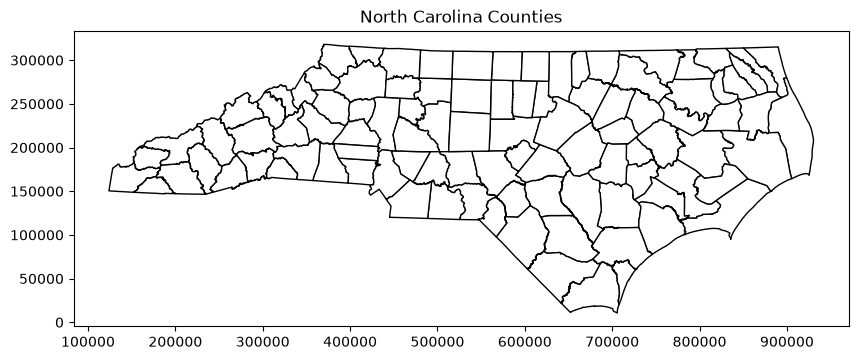

In [3]:
# Load NC county boundaries
counties = gpd.read_file("data/counties_nc.json")

# Check the coordinate reference system
print(counties.crs)

nc_counties = counties.to_crs(epsg=32119)

# Plot NC counties
nc_counties.plot(
    edgecolor="black",
    facecolor="white",
    figsize=(10, 6)
)

plt.title("North Carolina Counties")
plt.show()


In [4]:
print(nc_counties.columns.tolist())

['OBJECTID', 'County', 'FIPS', 'Rec_Survey', 'NCGS_url', 'ck_date', 'Shape__Area', 'Shape__Length', 'GlobalID', 'geometry']


In [5]:
print(kalmia_latifolia.columns.tolist())

['gbifID', 'datasetKey', 'occurrenceID', 'kingdom', 'phylum', 'class', 'order', 'family', 'genus', 'species', 'infraspecificEpithet', 'taxonRank', 'scientificName', 'verbatimScientificName', 'verbatimScientificNameAuthorship', 'countryCode', 'locality', 'stateProvince', 'occurrenceStatus', 'individualCount', 'publishingOrgKey', 'decimalLatitude', 'decimalLongitude', 'coordinateUncertaintyInMeters', 'coordinatePrecision', 'elevation', 'elevationAccuracy', 'depth', 'depthAccuracy', 'eventDate', 'day', 'month', 'year', 'taxonKey', 'speciesKey', 'basisOfRecord', 'institutionCode', 'collectionCode', 'catalogNumber', 'recordNumber', 'identifiedBy', 'dateIdentified', 'license', 'rightsHolder', 'recordedBy', 'typeStatus', 'establishmentMeans', 'lastInterpreted', 'mediaType', 'issue']


In [6]:
# Add species names
kalmia_latifolia["queried_species"] = "Kalmia latifolia"
pueraria_montana["queried_species"] = "Pueraria montana"

# Combine the two datasets
species_df = pd.concat(
    [kalmia_latifolia, pueraria_montana],
    ignore_index=True
)

# Keep the columns needed for mapping
species_df = species_df[
    ["queried_species", "decimalLongitude", "decimalLatitude"]
].copy()

# Ensure coordinates are numeric
species_df["decimalLongitude"] = pd.to_numeric(
    species_df["decimalLongitude"], errors="coerce"
)
species_df["decimalLatitude"] = pd.to_numeric(
    species_df["decimalLatitude"], errors="coerce"
)

# Remove missing or invalid coordinates
species_df = species_df.dropna(
    subset=["decimalLongitude", "decimalLatitude"]
)

species_df = species_df[
    species_df["decimalLongitude"].between(-180, 180)
    & species_df["decimalLatitude"].between(-90, 90)
].copy()

species_df.head()


,queried_species,decimalLongitude,decimalLatitude
0,Kalmia latifolia,-81.689445,36.211842
1,Kalmia latifolia,-83.436408,35.052953
2,Kalmia latifolia,-83.018630,35.036863
3,Kalmia latifolia,-82.542068,35.489355
4,Kalmia latifolia,-83.277262,35.427997


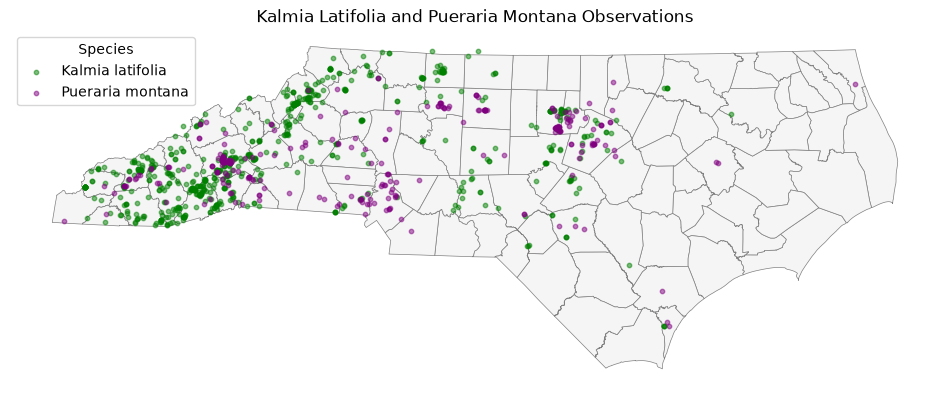

In [7]:
# Create a GeoDataFrame from latitude and longitude
species_points = gpd.GeoDataFrame(
    species_df.copy(),
    geometry=gpd.points_from_xy(
        species_df["decimalLongitude"],
        species_df["decimalLatitude"]
    ),
    crs="EPSG:4326"
)

# Match NC counties CRS
species_points = species_points.to_crs(nc_counties.crs)

# Plot observations over county boundaries
fig, ax = plt.subplots(figsize=(12, 6))

nc_counties.plot(
    ax=ax,
    facecolor="whitesmoke",
    edgecolor="gray",
    linewidth=0.5
)

colors = {
    "Kalmia latifolia": "green",
    "Pueraria montana": "purple"
}

for species, color in colors.items():
    species_points.loc[
        species_points["queried_species"] == species
    ].plot(
        ax=ax,
        color=color,
        markersize=10,
        alpha=0.5,
        label=species
    )

ax.set_title("Kalmia Latifolia and Pueraria Montana Observations")
ax.legend(title="Species")
ax.set_axis_off()

plt.show()


In [8]:
# Assign each observation to an NC county- spatial join
points_by_county = gpd.sjoin(
    species_points,
    nc_counties[["County", "FIPS", "geometry"]],
    how="inner",
    predicate="within"
).drop(columns="index_right")

points_by_county.head()


,queried_species,decimalLongitude,decimalLatitude,geometry,County,FIPS
0,Kalmia latifolia,-81.689445,36.211842,POINT (367787.595 276382.364),Watauga,189
1,Kalmia latifolia,-83.436408,35.052953,POINT (205054.567 153577.746),Macon,113
2,Kalmia latifolia,-83.018630,35.036863,POINT (243056.729 150171.96),Jackson,099
3,Kalmia latifolia,-82.542068,35.489355,POINT (288295.537 198680.284),Buncombe,021
4,Kalmia latifolia,-83.277262,35.427997,POINT (221349.646 194506.23),Jackson,099


In [9]:
#count observations by county
counts = (
    points_by_county
    .groupby(["FIPS", "queried_species"])
    .size()
    .unstack(fill_value=0) #unstack the species column to create a separate column for each species, filling missing values with 0
    .reindex(
        columns=["Kalmia latifolia", "Pueraria montana"],
        fill_value=0
    )
)

counts.head()


queried_species,Kalmia latifolia,Pueraria montana
FIPS,,
001,2,0
003,6,0
005,3,0
009,13,0
011,35,0


In [10]:
%pip install mapclassify


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip3.14 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/geopandas/plotting.py:746: UserWarning: Numba not installed. Using slow pure python version.
  binning = mapclassify.classify(


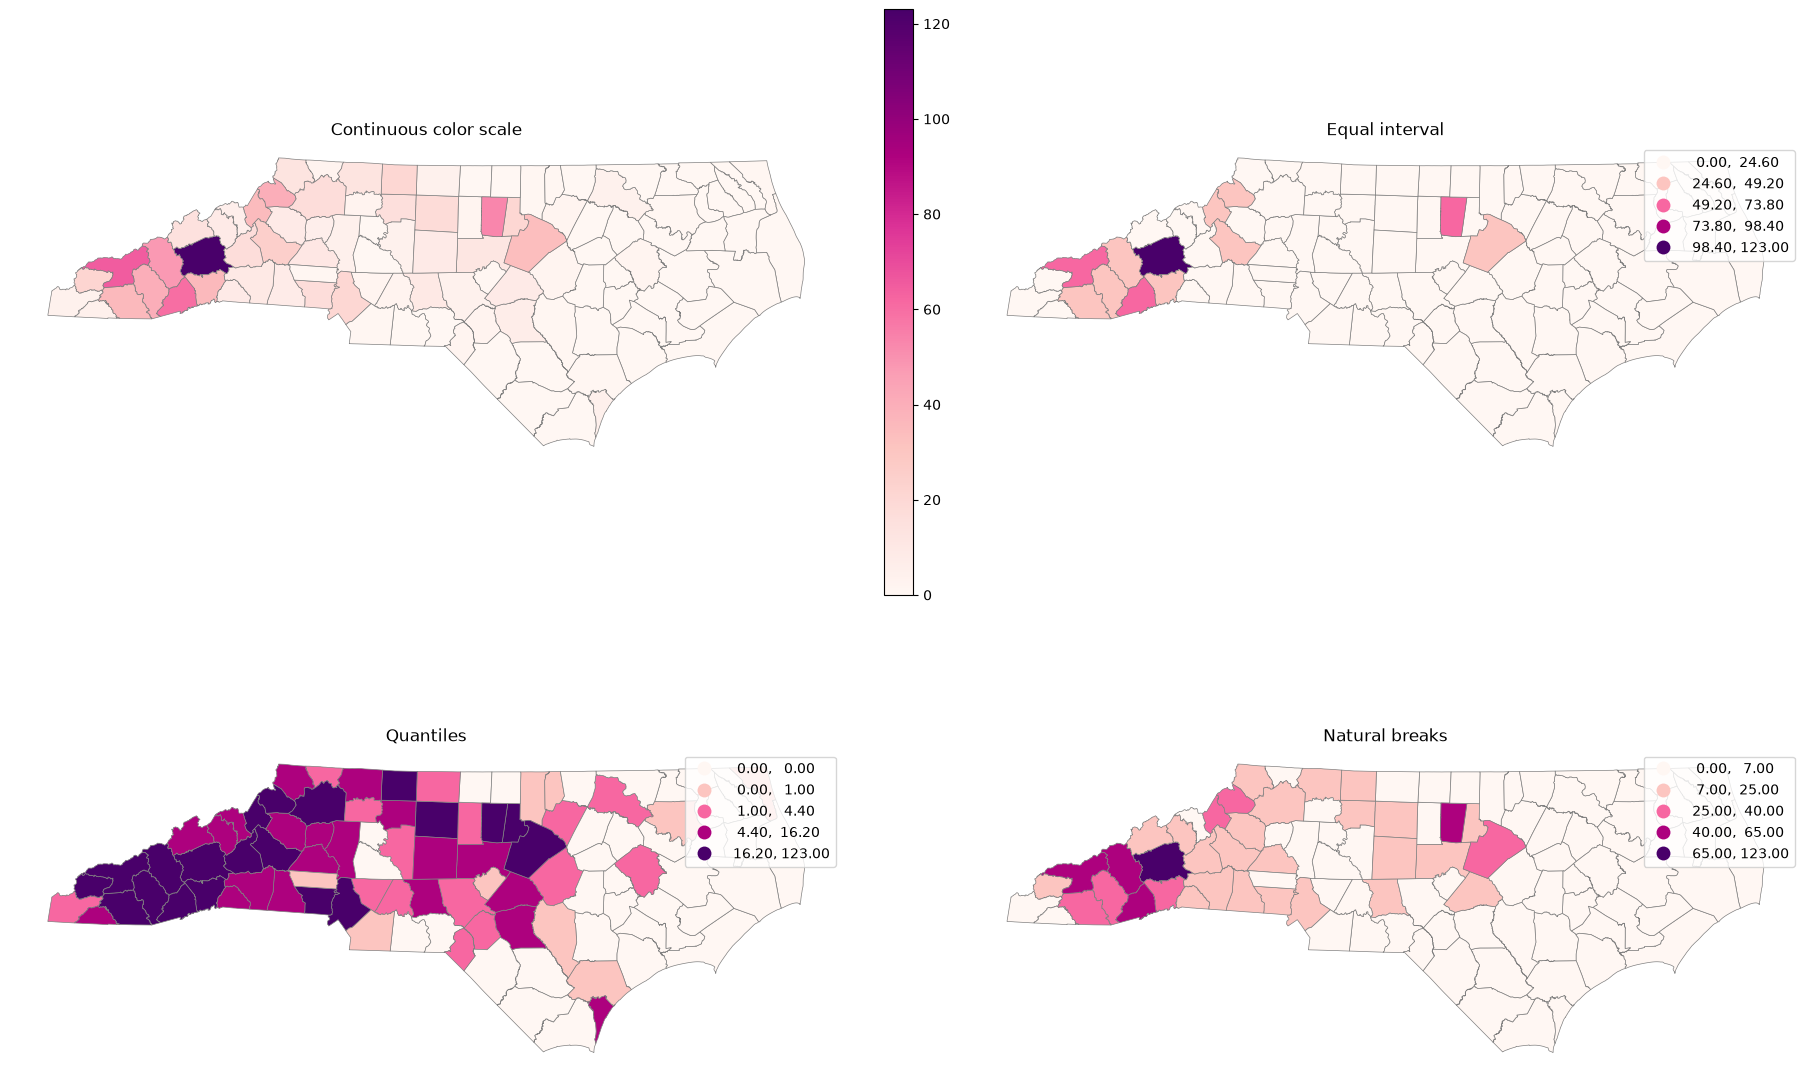

In [11]:
# Total observations of both species per county
totals = counts.sum(axis=1).rename("total")

# Join totals to NC county boundaries
county_map = nc_counties.merge(
    totals,
    left_on="FIPS",
    right_index=True, 
    how="left"
)

county_map["total"] = county_map["total"].fillna(0)

# Create four choropleths using AI
fig, axes = plt.subplots(
    2, 2,
    figsize=(18, 12),
    layout="constrained"
)

schemes = [
    (None, "Continuous color scale"),
    ("equalinterval", "Equal interval"),
    ("quantiles", "Quantiles"),
    ("fisherjenks", "Natural breaks")
]

for ax, (scheme, title) in zip(axes.flat, schemes):

    options = {
        "column": "total",
        "cmap": "RdPu",
        "edgecolor": "gray",
        "linewidth": 0.5,
        "legend": True,
        "ax": ax
    }

    if scheme is not None:
        options["scheme"] = scheme
        options["k"] = 5

    county_map.plot(**options)

    ax.set_title(title)
    ax.set_axis_off()

plt.savefig(
    "species_classification.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


Kalmia latifolia positive-count median: 6.0
Pueraria montana positive-count median: 3.0


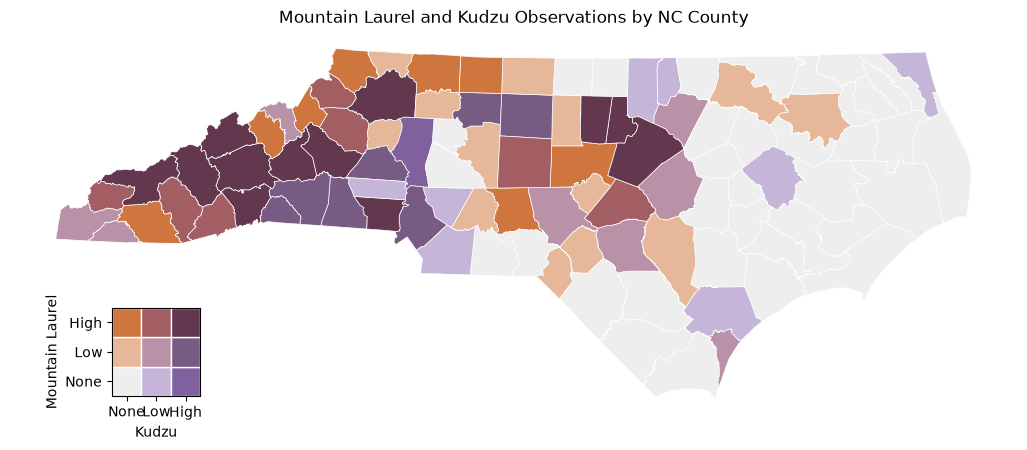

In [12]:
import numpy as np
from matplotlib.patches import Rectangle

# Attach species counts to county polygons
bivariate = nc_counties.merge(
    counts,
    left_on="FIPS",
    right_index=True,
    how="left"
)

species = ["Kalmia latifolia", "Pueraria montana"]
bivariate[species] = bivariate[species].fillna(0)

# Classify each species
for name in species:
    values = bivariate[name]
    median = values.loc[values > 0].median()

    bivariate[name + "_class"] = np.select(
        [values == 0, values <= median],
        [0, 1],
        default=2
    )

    print(name, "positive-count median:", median)

# Rows = increasing mountain laurel counts
# Columns = increasing kudzu counts
palette = np.array([
    ["#eeeeee", "#c5b5d8", "#80619e"],
    ["#e6b899", "#b992a8", "#785b82"],
    ["#cf763e", "#a35e63", "#63384f"]
])

bivariate["color"] = [
    palette[laurel, kudzu]
    for laurel, kudzu in zip(
        bivariate["Kalmia latifolia_class"],
        bivariate["Pueraria montana_class"]
    )
]

fig, ax = plt.subplots(figsize=(13, 8))

bivariate.plot(
    color=bivariate["color"],
    edgecolor="white",
    linewidth=0.5,
    ax=ax
)

ax.set_title(
    "Mountain Laurel and Kudzu Observations by NC County"
)
ax.set_axis_off()

# Create bivariate legend
legend_ax = ax.inset_axes([0.05, 0.05, 0.19, 0.23])

for laurel in range(3):
    for kudzu in range(3):
        legend_ax.add_patch(
            Rectangle(
                (kudzu, laurel), 1, 1,
                facecolor=palette[laurel, kudzu],
                edgecolor="white"
            )
        )

legend_ax.set_xlim(0, 3)
legend_ax.set_ylim(0, 3)
legend_ax.set_aspect("equal")

legend_ax.set_xticks([0.5, 1.5, 2.5])
legend_ax.set_xticklabels(["None", "Low", "High"])
legend_ax.set_yticks([0.5, 1.5, 2.5])
legend_ax.set_yticklabels(["None", "Low", "High"])

legend_ax.set_xlabel("Kudzu")
legend_ax.set_ylabel("Mountain Laurel")

plt.savefig(
    "species_bivariate.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()



Classification schemes can influence our interpretation of species populations by exaggerating differences to make them appear larger, even if recorded data is similar. For example, the quantile map makes the western concentration of observations appear much more widespread, while the other three maps emphasize a smaller number of counties with high counts.

## Assignment #2:
Generate two pngs, one of a proportional symbol and another of a hexagon map.

In [13]:
# Total observations per county
totals = counts.sum(axis=1).rename("total")

# Join totals to NC county boundaries
county_map = nc_counties.merge(
    totals,
    left_on="FIPS",
    right_index=True,
    how="left"
)

county_map["total"] = county_map["total"].fillna(0)

county_map.head()


,OBJECTID,County,FIPS,Rec_Survey,NCGS_url,ck_date,Shape__Area,Shape__Length,GlobalID,geometry,total
0,1,Alamance,001,Recorded survey data is available. Visit North...,https://ncem-gis.maps.arcgis.com/apps/webappvi...,1736726400000,1.210717e+10,476733.362073,acd66e2b-e702-4b3a-82c1-eb86e12d3804,"POLYGON ((586315.778 268773.815, 586235.57 264...",2.0
1,2,Alexander,003,Recorded survey data is available. Visit North...,https://ncem-gis.maps.arcgis.com/apps/webappvi...,1736726400000,7.343450e+09,387342.137292,6a1dac25-2574-4182-b77b-0074a5482dac,"POLYGON ((418895.666 226840.947, 418876.13 226...",6.0
2,3,Alleghany,005,No recent survey data available,,1322524800000,6.576362e+09,439166.717185,d8e726fa-ac7d-4212-a981-6ea0b111cee0,"POLYGON ((407353.077 292575.889, 407390.077 29...",3.0
3,4,Anson,007,No recent survey data available,,1322524800000,1.497020e+10,575503.754866,e4518706-732a-4abe-9079-9de6523b4747,"POLYGON ((493337.769 161122.261, 493357.278 16...",0.0
4,5,Ashe,009,Recorded survey data is available. Visit North...,https://ncem-gis.maps.arcgis.com/apps/webappvi...,1736726400000,1.193926e+10,520084.244333,6d39c7ea-b7f4-4ac8-be47-65dfe4a46074,"POLYGON ((386935.501 279038.53, 386128.989 279...",13.0


In [14]:

# Convert county polygons to centroid points
centers = county_map.geometry.centroid

centers.head()

0    POINT (573607.797 254509.136)
1    POINT (413141.438 243000.333)
2    POINT (418938.773 306161.549)
3    POINT (508921.389 136308.837)
4    POINT (385394.828 300628.014)
dtype: geometry

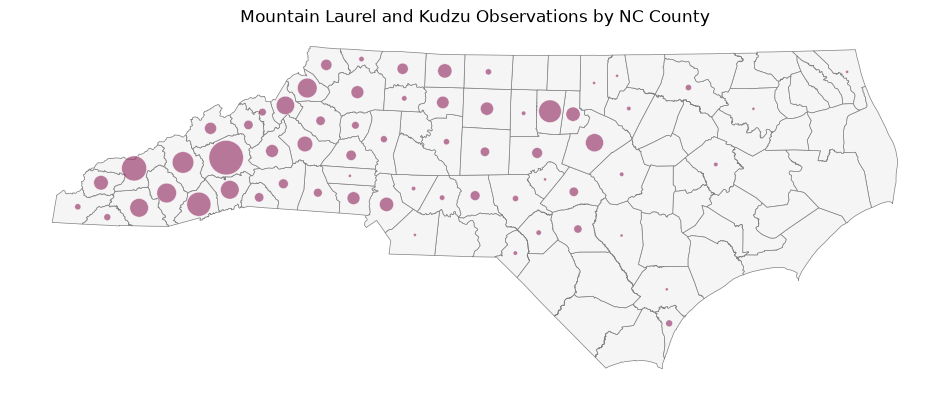

In [ ]:
#Proportional Symbol Map
def propSymbolMap(ax):

    # Plot county boundaries
    county_map.plot(
        ax=ax,
        facecolor="whitesmoke",
        edgecolor="gray",
        linewidth=0.5
    )

    # Plot proportional circles
    ax.scatter(
        centers.x,
        centers.y,
        s=county_map["total"] * 5, #makes the area of each circle proportional to the number of observations in that county
        color="#8e235c",
        alpha=0.6,
        edgecolors="white",
        linewidths=0.5
    )

    ax.set_title(
        "Mountain Laurel and Kudzu Observations by NC County"
    )
    ax.set_axis_off()

    return ax


fig, ax = plt.subplots(figsize=(12, 7))

propSymbolMap(ax)

plt.savefig(
    "species_proportional_symbols.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

#Total observations per county, with larger circles representing more records

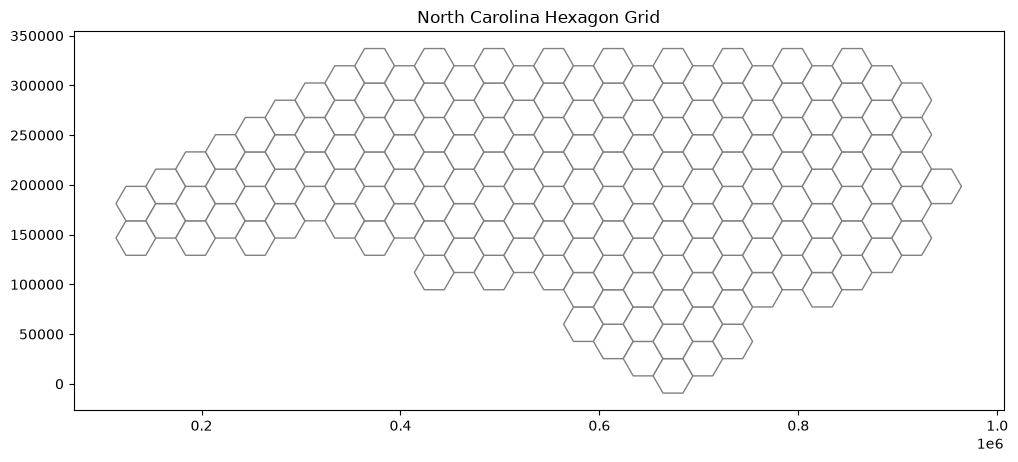

In [ ]:
#create a hexagonal grid over NC counties
import numpy as np
from shapely.geometry import Polygon

# Set geographic boundaries and points
states = nc_counties
points = points_by_county.copy()

# Hexagon radius in meters
radius = 20000

xmin, ymin, xmax, ymax = states.total_bounds
hexagons = []

for column, x in enumerate(
    np.arange(xmin - radius, xmax + 2 * radius, 1.5 * radius)
):
    for y in np.arange(
        ymin - radius, ymax + 2 * radius,
        np.sqrt(3) * radius
    ):

        # Offset alternating columns
        center_y = (
            y + (column % 2) * np.sqrt(3) * radius / 2
        )

        angles = np.arange(6) * np.pi / 3

        hexagons.append(
            Polygon([
                (
                    x + radius * np.cos(angle),
                    center_y + radius * np.sin(angle)
                )
                for angle in angles
            ])
        )

# Create GeoDataFrame
grid = gpd.GeoDataFrame(
    {"hex_id": range(len(hexagons))},
    geometry=hexagons,
    crs=states.crs
)

# Keep hexagons that intersect NC
region = states.geometry.union_all()

grid = grid.loc[
    grid.intersects(region)
].copy()

grid.plot(
    edgecolor="gray",
    facecolor="white",
    figsize=(12, 7)
)

plt.title("North Carolina Hexagon Grid")
plt.show()


In [ ]:

# Give each observation a unique ID
points = points.reset_index(drop=True)
points["point_id"] = points.index

# Spatial join points to hexagons
joined = gpd.sjoin(
    points,
    grid[["hex_id", "geometry"]],
    how="inner",
    predicate="intersects"
)

# Avoid counting points twice on shared edges
joined = (
    joined.sort_values("hex_id")
    .drop_duplicates("point_id")
)

# Count records by hexagon and species
hex_counts = (
    joined.groupby(["hex_id", "queried_species"])
    .size()
    .unstack(fill_value=0)
    .reindex(
        columns=["Kalmia latifolia", "Pueraria montana"],
        fill_value=0
    )
)

# Join counts to hexagon grid
grid = grid.merge(
    hex_counts,
    left_on="hex_id",
    right_index=True,
    how="left"
)

species = ["Kalmia latifolia", "Pueraria montana"]

grid[species] = grid[species].fillna(0)

# Calculate total observations
grid["total"] = grid[species].sum(axis=1)

grid.head()


,hex_id,geometry,Kalmia latifolia,Pueraria montana,total
15,15,"POLYGON ((154002.483 146549.655, 144002.483 16...",0.0,1.0,1.0
16,16,"POLYGON ((154002.483 181190.671, 144002.483 19...",0.0,0.0,0.0
27,27,"POLYGON ((184002.483 163870.163, 174002.483 18...",5.0,1.0,6.0
28,28,"POLYGON ((184002.483 198511.179, 174002.483 21...",24.0,1.0,25.0
37,37,"POLYGON ((214002.483 146549.655, 204002.483 16...",11.0,0.0,11.0


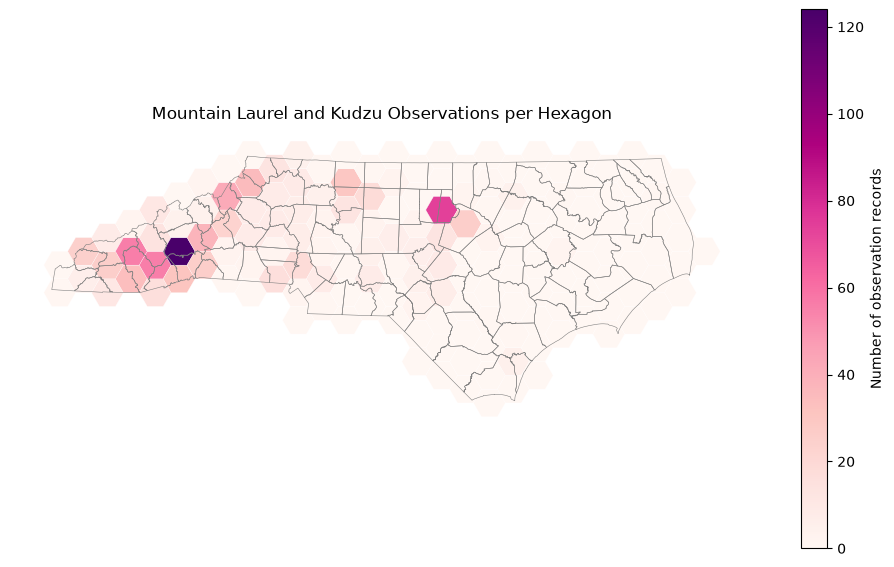

In [ ]:
def hexCountMap(ax, grid, states):

    grid.plot(
        ax=ax,
        column="total",
        cmap="RdPu",
        edgecolor="white",
        linewidth=0.2,
        legend=True,
        legend_kwds={
            "label": "Number of observation records"
        }
    )

    # Add NC county boundaries
    states.boundary.plot(
        ax=ax,
        color="gray",
        linewidth=0.4
    )

    ax.set_title(
        "Mountain Laurel and Kudzu Observations per Hexagon"
    )
    ax.set_axis_off()

    return ax


fig, ax = plt.subplots(figsize=(12, 7))

hexCountMap(ax, grid, states)

plt.savefig(
    "species_hexagon_map.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

#Observations aggregated into equally sized geographic cells

In [ ]:
#checking map observations
print("County observations:", county_map["total"].sum())
print("Hexagon observations:", grid["total"].sum())

County observations: 989.0
Hexagon observations: 989.0
